In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [32]:
DATA_PATH = Path('../src/clean_data.csv')
FS = 360

In [33]:
df = pd.read_csv(DATA_PATH, index_col=0)

signal_columns = sorted(
    [c for c in df.columns if c.startswith('x_')],
    key=lambda c: int(c.split('_')[1])
)

print(f'Liczba uderzeń: {len(df):,}')
print(f'Liczba rekordów: {df["record_id"].nunique()}')
print(f'Liczba próbek w segmencie: {len(signal_columns)}')
print(f'Czas segmentu: {len(signal_columns) / FS:.3f} s')
print(f'Zakres record_id: {df["record_id"].min()}-{df["record_id"].max()}')

df.head()

Liczba uderzeń: 93,506
Liczba rekordów: 46
Liczba próbek w segmencie: 180
Czas segmentu: 0.500 s
Zakres record_id: 100-234


,record_id,r_peak,annotation_sample,type,dist_from_annotation,x_0,x_1,x_2,x_3,x_4,...,x_171,x_172,x_173,x_174,x_175,x_176,x_177,x_178,x_179,anomaly
0,100,370,370.0,N,0.0,-0.280,-0.295,-0.305,-0.315,-0.305,...,-0.455,-0.450,-0.435,-0.445,-0.450,-0.455,-0.470,-0.460,-0.455,0
1,100,663,662.0,N,1.0,-0.335,-0.330,-0.335,-0.345,-0.345,...,-0.435,-0.430,-0.435,-0.420,-0.420,-0.420,-0.420,-0.425,-0.425,0
2,100,947,946.0,N,1.0,-0.345,-0.345,-0.345,-0.340,-0.310,...,-0.375,-0.365,-0.370,-0.385,-0.395,-0.385,-0.385,-0.370,-0.365,0
3,100,1231,1231.0,N,0.0,-0.330,-0.320,-0.290,-0.290,-0.300,...,-0.470,-0.455,-0.460,-0.440,-0.435,-0.425,-0.430,-0.445,-0.450,0
4,100,1515,1515.0,N,0.0,-0.320,-0.310,-0.305,-0.305,-0.275,...,-0.445,-0.440,-0.435,-0.430,-0.430,-0.450,-0.445,-0.445,-0.435,0


In [34]:
summary = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing_n': df.isna().sum(),
    'missing_pct': 100 * df.isna().mean(),
    'unique_n': df.nunique(dropna=False)
})
summary.loc[['record_id', 'r_peak', 'annotation_sample', 'type', 'dist_from_annotation', 'anomaly']]

,dtype,missing_n,missing_pct,unique_n
record_id,int64,0,0.0,46
r_peak,int64,0,0.0,87367
annotation_sample,float64,0,0.0,87284
type,str,0,0.0,5
dist_from_annotation,float64,0,0.0,49
anomaly,int64,0,0.0,2


In [35]:
duplicate_beats = df.duplicated(subset=['record_id', 'r_peak']).sum()
missing_signal = df[signal_columns].isna().sum().sum()
inf_signal = np.isinf(df[signal_columns].to_numpy(dtype=float)).sum()

print('Duplikaty (record_id, r_peak): ', duplicate_beats)
print('Brakujące wartości w próbkach EKG: ', missing_signal)
print('Wartości nieskończone w próbkach EKG: ', inf_signal)

Duplikaty (record_id, r_peak):  0
Brakujące wartości w próbkach EKG:  0
Wartości nieskończone w próbkach EKG:  0


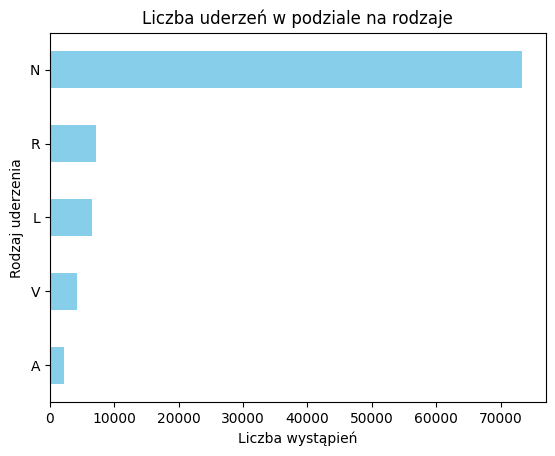

In [36]:
counts = df['type'].value_counts().sort_values()

counts.plot(kind='barh', color='skyblue')
plt.ylabel('Rodzaj uderzenia')
plt.xlabel('Liczba wystąpień')
plt.title('Liczba uderzeń w podziale na rodzaje')
plt.show()

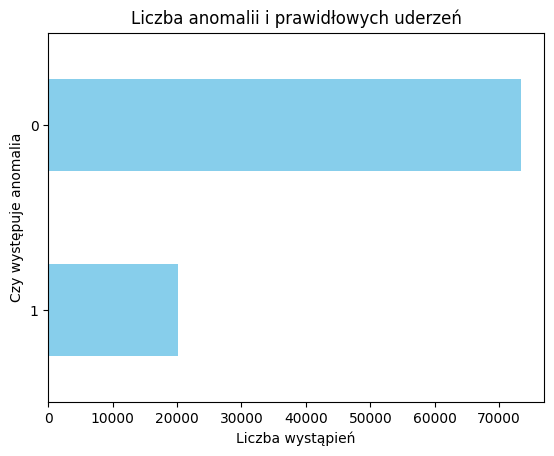

In [37]:
anomalies = df['anomaly'].value_counts().sort_values()

anomalies.plot(kind='barh', color='skyblue')
plt.ylabel('Czy występuje anomalia')
plt.xlabel('Liczba wystąpień')
plt.title('Liczba anomalii i prawidłowych uderzeń')
plt.show()

In [38]:
anomaly_pct = anomalies[1] / (anomalies[0]+anomalies[1]) * 100

print(f'Uderzenia anomalne stanowią {round(anomaly_pct,2)}% wszystkich uderzeń')

Uderzenia anomalne stanowią 21.6% wszystkich uderzeń


In [39]:
record_id_agg = (
    df.groupby('record_id')
    .agg(
        beats=('anomaly','size'),
        normal=('anomaly', lambda x: (x==0).sum()),
        anomaly=('anomaly', lambda x: (x==1).sum()),
    )
)
record_id_agg['anomaly_pct'] = round(record_id_agg['anomaly'] / record_id_agg['beats'] * 100, 2)

record_id_agg.sort_values('anomaly_pct', ascending=False)

,beats,normal,anomaly,anomaly_pct
record_id,,,,
107,16,0,16,100.00
109,2520,0,2520,100.00
111,2017,0,2017,100.00
207,138,0,138,100.00
124,1541,0,1541,100.00
118,2276,0,2276,100.00
214,2129,0,2129,100.00
232,1776,0,1776,100.00
231,1570,314,1256,80.00


In [40]:
crosstab = pd.crosstab(df['record_id'], df['type'])
crosstab

type,A,L,N,R,V
record_id,,,,,
100,33,0,2237,0,0
101,3,0,1859,0,0
103,2,0,2082,0,0
105,0,0,2457,0,41
106,0,0,1505,0,419
107,0,0,0,0,16
108,3,0,1366,0,9
109,0,2491,0,0,29
111,0,2016,0,0,1


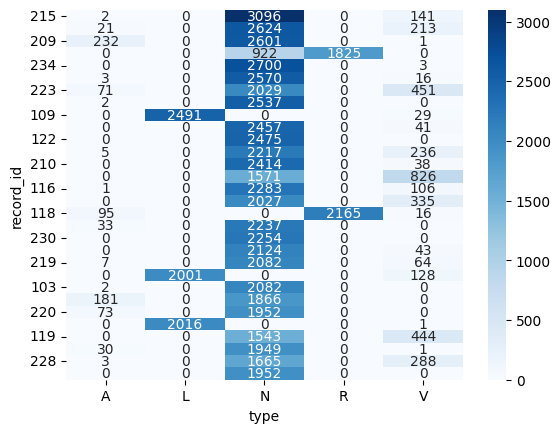

In [46]:
top_ids = crosstab.sum(axis=1).nlargest(30).index

ct_top = crosstab.loc[top_ids]

sns.heatmap(
    ct_top,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.show()